<a href="https://colab.research.google.com/github/shilpathota/toolrl-grpo-reward-granularity/blob/main/ToolRL_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ToolRL: Reward is All Tool Learning Needs
## Link to this paper - https://arxiv.org/pdf/2504.13958




In [70]:
!nvidia-smi

Tue Oct 13 19:40:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             32W /   70W |    2077MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [71]:
!pip install -q -U \
    transformers \
    datasets \
    trl \
    peft \
    accelerate \
    bitsandbytes

In [72]:
import torch
import transformers
import trl
import datasets
import peft

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("TRL:", trl.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.11.0+cu130
Transformers: 5.19.0
TRL: 1.15.0
CUDA: True
GPU: Tesla T4


### TRL has native GRPOTrainer support and custom reward functions, which is exactly what we need.

In [73]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [74]:
def calculator(expression: str):
    """Evaluate a simple arithmetic expression."""
    try:
        return str(eval(expression, {"__builtins__": {}}, {}))
    except Exception:
        return "ERROR"


def get_weather(city: str, day: str):
    """Return synthetic weather data."""
    weather_db = {
        ("Chicago", "today"): "sunny",
        ("Chicago", "tomorrow"): "rainy",
        ("New York", "today"): "cloudy",
        ("New York", "tomorrow"): "sunny",
    }
    return weather_db.get((city, day), "unknown")


def lookup_population(city: str):
    """Return synthetic city population."""
    database = {
        "Chicago": 2665000,
        "New York": 8258000,
        "Los Angeles": 3820000,
    }
    return database.get(city, -1)


def convert_temperature(value: float, unit: str):
    """Convert Celsius to Fahrenheit or Fahrenheit to Celsius."""
    if unit == "C_to_F":
        return value * 9 / 5 + 32
    elif unit == "F_to_C":
        return (value - 32) * 5 / 9
    return None

In [75]:
SYSTEM_PROMPT = """
You are a tool-using assistant.

Choose exactly one tool when a tool is required.

Return ONLY valid JSON in this format:

{
  "tool": "<tool_name>",
  "arguments": {
    "<argument_name>": "<argument_value>"
  }
}

Available tools:

calculator(expression)
get_weather(city, day)
lookup_population(city)
convert_temperature(value, unit)
"""

Synthetic Data set

In [76]:
examples = []

# Calculator tasks
for a in range(10, 40):
    for b in range(2, 8):
        examples.append({
            "question": f"What is {a} multiplied by {b}?",
            "gold_tool": "calculator",
            "gold_arguments": {
                "expression": f"{a}*{b}"
            }
        })

# Weather tasks
cities = ["Chicago", "New York"]
days = ["today", "tomorrow"]

for city in cities:
    for day in days:
        for _ in range(30):
            examples.append({
                "question": f"What is the weather in {city} {day}?",
                "gold_tool": "get_weather",
                "gold_arguments": {
                    "city": city,
                    "day": day
                }
            })

# Population
cities_population = ["Chicago", "New York", "Los Angeles"]

for city in cities_population:
    for _ in range(40):
        examples.append({
            "question": f"What is the population of {city}?",
            "gold_tool": "lookup_population",
            "gold_arguments": {
                "city": city
            }
        })

# Temperature conversion
for value in range(0, 35, 5):
    examples.append({
        "question": f"Convert {value} Celsius to Fahrenheit.",
        "gold_tool": "convert_temperature",
        "gold_arguments": {
            "value": float(value),
            "unit": "C_to_F"
        }
    })

random.shuffle(examples)

len(examples)

427

Building hugging face dataset

In [77]:
from datasets import Dataset

dataset = Dataset.from_list(examples)

dataset

Dataset({
    features: ['question', 'gold_tool', 'gold_arguments'],
    num_rows: 427
})

split the dataset

In [78]:
split = dataset.train_test_split(
    test_size=0.2,
    seed=SEED
)

train_dataset = split["train"]
test_dataset = split["test"]

print(len(train_dataset))
print(len(test_dataset))

341
86


Format the prompts

In [79]:
def create_prompt(example):
    prompt = f"""
{SYSTEM_PROMPT}

User request:
{example['question']}
"""

    return {
        "prompt": prompt,
        "gold_tool": example["gold_tool"],
        "gold_arguments": example["gold_arguments"]
    }

apply this to dataset

In [80]:
train_dataset = train_dataset.map(create_prompt)
test_dataset = test_dataset.map(create_prompt)

Map:   0%|          | 0/341 [00:00<?, ? examples/s]

Map:   0%|          | 0/86 [00:00<?, ? examples/s]

Inspect the dataset

In [81]:
print(train_dataset[0]["prompt"])
print(train_dataset[0]["gold_tool"])
print(train_dataset[0]["gold_arguments"])



You are a tool-using assistant.

Choose exactly one tool when a tool is required.

Return ONLY valid JSON in this format:

{
  "tool": "<tool_name>",
  "arguments": {
    "<argument_name>": "<argument_value>"
  }
}

Available tools:

calculator(expression)
get_weather(city, day)
lookup_population(city)
convert_temperature(value, unit)


User request:
What is 28 multiplied by 4?

calculator
{'city': None, 'expression': '28*4', 'day': None, 'value': None, 'unit': None}


Parsing the JSON

In [82]:
import json
import re

def extract_json(text):
    if isinstance(text, list):
        # Some TRL versions return chat messages.
        text = text[-1].get("content", "")

    if not isinstance(text, str):
        text = str(text)

    # Remove markdown fences
    text = text.replace("```json", "").replace("```", "").strip()

    # Try direct JSON
    try:
        return json.loads(text)
    except Exception:
        pass

    # Try extracting first JSON object
    match = re.search(r"\{.*\}", text, re.DOTALL)

    if match:
        try:
            return json.loads(match.group())
        except Exception:
            return None

    return None

Testing JSON

In [83]:
extract_json(
    '{"tool":"calculator","arguments":{"expression":"37*18"}}'
)

{'tool': 'calculator', 'arguments': {'expression': '37*18'}}

In [84]:
# NEW CELL — normalize gold arguments and compare values safely

def clean_arguments(args):
    """
    Remove unused argument fields stored as None by Hugging Face Dataset.
    Example:
    {'city': 'Chicago', 'day': None}
    becomes:
    {'city': 'Chicago'}
    """
    if args is None:
        return {}

    return {
        key: value
        for key, value in args.items()
        if value is not None
    }


def values_equal(pred, gold, key=None):
    """
    Compare predicted and gold values with light normalization.
    """

    # Calculator expressions:
    # "18 * 4" should equal "18*4"
    if key == "expression":
        return (
            str(pred).replace(" ", "")
            ==
            str(gold).replace(" ", "")
        )

    # Numeric values
    if isinstance(pred, (int, float)) and isinstance(gold, (int, float)):
        return abs(float(pred) - float(gold)) < 1e-6

    # Strings
    return (
        str(pred).strip().lower()
        ==
        str(gold).strip().lower()
    )

Implementing Coarse reward

In [85]:
# UPDATED COARSE REWARD

def coarse_reward(
    completions,
    gold_tool,
    gold_arguments,
    **kwargs
):
    rewards = []

    for completion, expected_tool, expected_args in zip(
        completions,
        gold_tool,
        gold_arguments
    ):
        # IMPORTANT FIX
        expected_args = clean_arguments(expected_args)

        parsed = extract_json(completion)

        if parsed is None:
            rewards.append(0.0)
            continue

        predicted_tool = parsed.get("tool")
        predicted_args = parsed.get("arguments", {})

        args_match = (
            set(predicted_args.keys())
            ==
            set(expected_args.keys())
        )

        if args_match:
            args_match = all(
                values_equal(
                    predicted_args[key],
                    expected_args[key],
                    key
                )
                for key in expected_args
            )

        correct = (
            predicted_tool == expected_tool
            and args_match
        )

        rewards.append(
            1.0 if correct else 0.0
        )

    return rewards

Implementing Fine-Grained reward

In [86]:
# UPDATED FINE REWARD

def fine_reward(
    completions,
    gold_tool,
    gold_arguments,
    **kwargs
):
    rewards = []

    for completion, expected_tool, expected_args in zip(
        completions,
        gold_tool,
        gold_arguments
    ):
        # IMPORTANT FIX
        expected_args = clean_arguments(expected_args)

        reward = 0.0

        parsed = extract_json(completion)

        # Invalid JSON
        if parsed is None:
            rewards.append(0.0)
            continue

        # 1. Valid JSON format
        reward += 0.2

        predicted_tool = parsed.get("tool")
        predicted_args = parsed.get("arguments", {})

        # 2. Correct tool
        if predicted_tool == expected_tool:
            reward += 0.3

        # 3. Argument-name reward
        expected_keys = set(expected_args.keys())
        predicted_keys = set(predicted_args.keys())

        if expected_keys == predicted_keys:
            reward += 0.2

        elif len(expected_keys) > 0:
            overlap = (
                len(expected_keys & predicted_keys)
                / len(expected_keys)
            )

            reward += 0.2 * overlap

        # 4. Individual argument-value reward
        if expected_keys:
            correct_values = 0

            for key in expected_keys:
                if key in predicted_args:

                    if values_equal(
                        predicted_args[key],
                        expected_args[key],
                        key
                    ):
                        correct_values += 1

            reward += 0.3 * (
                correct_values / len(expected_keys)
            )

        rewards.append(float(reward))

    return rewards

Checking the tool call

In [87]:
gold_tool = ["get_weather"]

gold_args = [{
    "city": "Chicago",
    "day": "tomorrow"
}]

Prediction

In [88]:
prediction = [
    '{"tool":"get_weather","arguments":{"city":"Chicago","day":"today"}}'
]

Run

In [89]:
print(
    coarse_reward(
        prediction,
        gold_tool,
        gold_args
    )
)

print(
    fine_reward(
        prediction,
        gold_tool,
        gold_args
    )
)

[0.0]
[0.85]


Load Qwen with LoRA

In [90]:
from peft import LoraConfig

peft_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ]
)

In [91]:
!pip install trl

In [92]:
import trl
import inspect
from trl import GRPOConfig

print("TRL version:", trl.__version__)
print(inspect.signature(GRPOConfig))

TRL version: 1.15.0
(output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 1e-06, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool | None = None, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = True, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = None, torch_compile: boo

Configuring GRPO

In [93]:
from trl import GRPOConfig
import torch

training_args = GRPOConfig(
    output_dir="/content/toolrl_fine",

    # Optimization
    learning_rate=5e-5,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,

    # GRPO rollout settings
    num_generations=4,
    generation_batch_size=4,

    # Generation
    max_completion_length=128,
    temperature=1.0,
    top_p=1.0,

    # Important: use actual GRPO objective
    loss_type="grpo",

    # Group-relative reward normalization
    scale_rewards="group",

    # PPO/GRPO clipping
    epsilon=0.2,

    # Memory
    gradient_checkpointing=True,
    use_vllm=False,

    # Logging
    logging_steps=5,
    save_steps=100,
    report_to="none",

    # Reproducibility
    seed=42,

    # Precision
    fp16=torch.cuda.is_available(),
)

First run with small dataset

In [94]:
train_small = train_dataset.select(
    range(min(200, len(train_dataset)))
)

In [95]:
!pip uninstall -y torchao

In [96]:
import torch
import trl
import peft

print("Torch:", torch.__version__)
print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.11.0+cu130
TRL: 1.15.0
PEFT: 0.21.2
CUDA: True
GPU: Tesla T4


Run fine-grained GRPO

In [97]:
from trl import GRPOTrainer

fine_trainer = GRPOTrainer(
    model="Qwen/Qwen2.5-0.5B-Instruct",
    args=training_args,
    train_dataset=train_small,
    reward_funcs=fine_reward,
    peft_config=peft_config,
)

fine_trainer.train()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.000000
10,0.000000
15,0.000000
20,0.000000
25,0.000000
30,0.000000
35,-0.000000
40,0.000000
45,0.000000
50,0.000000


TrainOutput(global_step=200, training_loss=1.862645149230957e-09, metrics={'train_runtime': 741.0704, 'train_samples_per_second': 0.27, 'train_steps_per_second': 0.27, 'total_flos': 0.0, 'train_loss': 1.862645149230957e-09, 'epoch': 1.0})

In [98]:
import os

os.makedirs("/content/drive/MyDrive/ToolRL", exist_ok=True)

fine_trainer.save_model(
    "/content/drive/MyDrive/ToolRL/fine_reward"
)

In [99]:
# Cell 1 — Free previous trainer/model from GPU

import gc
import torch

try:
    del fine_trainer
except:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared")

GPU cache cleared


TRain the Coarse Model

In [100]:
from trl import GRPOConfig

coarse_training_args = GRPOConfig(
    output_dir="/content/toolrl_coarse",

    learning_rate=5e-5,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,

    num_generations=4,
    generation_batch_size=4,

    max_completion_length=128,
    temperature=1.0,
    top_p=1.0,

    loss_type="grpo",
    scale_rewards="group",
    epsilon=0.2,

    gradient_checkpointing=True,
    use_vllm=False,

    logging_steps=5,
    save_steps=100,
    report_to="none",

    seed=42,
    fp16=torch.cuda.is_available(),
)

In [101]:
from trl import GRPOTrainer

coarse_trainer = GRPOTrainer(
    model="Qwen/Qwen2.5-0.5B-Instruct",
    args=coarse_training_args,
    train_dataset=train_small,
    reward_funcs=coarse_reward,
    peft_config=peft_config,
)

coarse_trainer.train()

coarse_trainer.save_model(
    "/content/drive/MyDrive/ToolRL/coarse_reward"
)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.000000
10,0.000000
15,-0.000000
20,0.000000
25,-0.000000
30,0.000000
35,0.000000
40,0.000000
45,-0.000000
50,0.000000


In [102]:

import gc
import torch

try:
    del coarse_trainer
except:
    pass

try:
    del fine_trainer
except:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared")

GPU cache cleared


Immediate Reward Function

In [103]:
# UPDATED INTERMEDIATE REWARD

def intermediate_reward(
    completions,
    gold_tool,
    gold_arguments,
    **kwargs
):
    rewards = []

    for completion, expected_tool, expected_args in zip(
        completions,
        gold_tool,
        gold_arguments
    ):
        # IMPORTANT FIX
        expected_args = clean_arguments(expected_args)

        parsed = extract_json(completion)

        if parsed is None:
            rewards.append(0.0)
            continue

        reward = 0.2

        predicted_tool = parsed.get("tool")
        predicted_args = parsed.get("arguments", {})

        # Correct tool
        if predicted_tool == expected_tool:
            reward += 0.3

        # Entire argument dictionary must match
        exact_args = (
            set(predicted_args.keys())
            ==
            set(expected_args.keys())
        )

        if exact_args:
            exact_args = all(
                values_equal(
                    predicted_args[key],
                    expected_args[key],
                    key
                )
                for key in expected_args
            )

        if exact_args:
            reward += 0.5

        rewards.append(float(reward))

    return rewards

Testing Immediate Reward Function

In [104]:
# Cell 3 — Sanity check intermediate reward

prediction = [
    '{"tool":"get_weather","arguments":{"city":"Chicago","day":"today"}}'
]

gold_tool = ["get_weather"]

gold_args = [{
    "city": "Chicago",
    "day": "tomorrow"
}]

print(
    intermediate_reward(
        prediction,
        gold_tool,
        gold_args
    )
)

[0.5]


Configure GRPO

In [105]:
# Cell 4 — Intermediate GRPO config

from trl import GRPOConfig
import torch

intermediate_training_args = GRPOConfig(
    output_dir="/content/toolrl_intermediate",

    learning_rate=5e-5,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,

    num_generations=4,
    generation_batch_size=4,

    max_completion_length=128,
    temperature=1.0,
    top_p=1.0,

    loss_type="grpo",
    scale_rewards="group",
    epsilon=0.2,

    gradient_checkpointing=True,
    use_vllm=False,

    logging_steps=5,
    save_steps=100,
    report_to="none",

    seed=42,
    fp16=torch.cuda.is_available(),
)

In [106]:
# Cell 5 — Create trainer

from trl import GRPOTrainer

intermediate_trainer = GRPOTrainer(
    model="Qwen/Qwen2.5-0.5B-Instruct",
    args=intermediate_training_args,
    train_dataset=train_small,
    reward_funcs=intermediate_reward,
    peft_config=peft_config,
)

# Cell 6 — Train

intermediate_trainer.train()

# Cell 7 — Save to Google Drive

import os

os.makedirs(
    "/content/drive/MyDrive/ToolRL",
    exist_ok=True
)

intermediate_trainer.save_model(
    "/content/drive/MyDrive/ToolRL/intermediate_reward"
)

print("Saved intermediate model")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.000000
10,0.000000
15,0.000000
20,0.000000
25,0.000000
30,0.000000
35,-0.000000
40,0.000000
45,0.000000
50,-0.000000


Saved intermediate model


### Evaluation

In [107]:
# Cell 1 — Imports

import json
import re
import torch
import pandas as pd

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

BASE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

FINE_PATH = "/content/drive/MyDrive/ToolRL/fine_reward"
INTERMEDIATE_PATH = "/content/drive/MyDrive/ToolRL/intermediate_reward"
COARSE_PATH = "/content/drive/MyDrive/ToolRL/coarse_reward"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

Device: cuda


Make sure drive is mounted

In [108]:
# Cell 2 — Mount Drive if needed

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


LOad Tokenizer once

In [109]:
# Cell 3 — Tokenizer

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded")

Tokenizer loaded


Keeping JSON Parser available

In [110]:
# Cell 4 — JSON parser

def extract_json(text):
    if isinstance(text, list):
        text = text[-1].get("content", "")

    if not isinstance(text, str):
        text = str(text)

    text = text.replace("```json", "").replace("```", "").strip()

    try:
        return json.loads(text)
    except Exception:
        pass

    match = re.search(r"\{.*\}", text, re.DOTALL)

    if match:
        try:
            return json.loads(match.group())
        except Exception:
            return None

    return None

Load the model

In [111]:
# Cell 5 — Model loader

def load_model(adapter_path=None):
    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )

    if adapter_path is not None:
        model = PeftModel.from_pretrained(
            base,
            adapter_path
        )
    else:
        model = base

    model.eval()
    return model

Defining Deterministic Generation

In [112]:
# Cell 6 — Generate one prediction

def generate_prediction(model, prompt):
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    inputs = {
        k: v.to(model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    text = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return text.strip()

Testing base model first

In [113]:
# Cell 7 — Quick sanity test

base_model = load_model()

sample_prompt = test_dataset[0]["prompt"]

prediction = generate_prediction(
    base_model,
    sample_prompt
)

print("PROMPT:")
print(sample_prompt)

print("\nMODEL OUTPUT:")
print(prediction)

print("\nPARSED:")
print(extract_json(prediction))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

PROMPT:


You are a tool-using assistant.

Choose exactly one tool when a tool is required.

Return ONLY valid JSON in this format:

{
  "tool": "<tool_name>",
  "arguments": {
    "<argument_name>": "<argument_value>"
  }
}

Available tools:

calculator(expression)
get_weather(city, day)
lookup_population(city)
convert_temperature(value, unit)


User request:
What is the population of Los Angeles?


MODEL OUTPUT:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}

PARSED:
{'tool': 'lookup_population', 'arguments': {'city': 'Los Angeles'}}


Defining Evalutaion metrics

In [114]:
# UPDATED EVALUATION

def evaluate_model(model, dataset):
    results = []

    valid_json = 0
    tool_correct = 0
    arg_names_correct = 0
    arg_values_correct = 0
    exact_call = 0

    for i, example in enumerate(dataset):

        prediction = generate_prediction(
            model,
            example["prompt"]
        )

        parsed = extract_json(prediction)

        gold_tool = example["gold_tool"]

        # IMPORTANT FIX
        gold_args = clean_arguments(
            example["gold_arguments"]
        )

        row = {
            "question": example["question"],
            "gold_tool": gold_tool,
            "gold_arguments": gold_args,
            "prediction": prediction,
            "parsed": parsed
        }

        if parsed is not None:
            valid_json += 1

            pred_tool = parsed.get("tool")
            pred_args = parsed.get("arguments", {})

            # Tool accuracy
            if pred_tool == gold_tool:
                tool_correct += 1

            # Argument-name accuracy
            if (
                set(pred_args.keys())
                ==
                set(gold_args.keys())
            ):
                arg_names_correct += 1

            # Argument-value accuracy
            values_match = True

            for key, gold_value in gold_args.items():

                if key not in pred_args:
                    values_match = False
                    break

                if not values_equal(
                    pred_args[key],
                    gold_value,
                    key
                ):
                    values_match = False
                    break

            if values_match:
                arg_values_correct += 1

            # Exact complete tool call
            exact_args = (
                set(pred_args.keys())
                ==
                set(gold_args.keys())
            )

            if exact_args:
                exact_args = all(
                    values_equal(
                        pred_args[key],
                        gold_args[key],
                        key
                    )
                    for key in gold_args
                )

            if (
                pred_tool == gold_tool
                and exact_args
            ):
                exact_call += 1

        results.append(row)

        if (i + 1) % 20 == 0:
            print(
                f"Evaluated {i + 1}/{len(dataset)}"
            )

    n = len(dataset)

    metrics = {
        "valid_json": valid_json / n,
        "tool_accuracy": tool_correct / n,
        "arg_name_accuracy": arg_names_correct / n,
        "arg_value_accuracy": arg_values_correct / n,
        "exact_call_accuracy": exact_call / n
    }

    return metrics, results

Evaluating Small dataset first

In [115]:
# Cell 9 — Small test subset first

eval_dataset = test_dataset.select(
    range(min(50, len(test_dataset)))
)

print("Evaluation examples:", len(eval_dataset))

Evaluation examples: 50


Evaluating base model

In [116]:
# Cell 10 — Evaluate base model

base_metrics, base_results = evaluate_model(
    base_model,
    eval_dataset
)

print(base_metrics)

Evaluated 20/50
Evaluated 40/50
{'valid_json': 0.98, 'tool_accuracy': 0.98, 'arg_name_accuracy': 0.98, 'arg_value_accuracy': 0.98, 'exact_call_accuracy': 0.98}


Free GPU memory

In [117]:
# Cell 11 — Free base model

import gc

del base_model
gc.collect()
torch.cuda.empty_cache()

Evalutate Fine reward model

In [118]:
# Cell 12 — Fine model

fine_model = load_model(FINE_PATH)

fine_metrics, fine_results = evaluate_model(
    fine_model,
    eval_dataset
)

print(fine_metrics)

del fine_model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Evaluated 20/50
Evaluated 40/50
{'valid_json': 1.0, 'tool_accuracy': 1.0, 'arg_name_accuracy': 1.0, 'arg_value_accuracy': 1.0, 'exact_call_accuracy': 1.0}


Evlautate intermediate model

In [119]:
# Cell 13 — Intermediate model

intermediate_model = load_model(
    INTERMEDIATE_PATH
)

intermediate_metrics, intermediate_results = evaluate_model(
    intermediate_model,
    eval_dataset
)

print(intermediate_metrics)

del intermediate_model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Evaluated 20/50
Evaluated 40/50
{'valid_json': 1.0, 'tool_accuracy': 1.0, 'arg_name_accuracy': 1.0, 'arg_value_accuracy': 1.0, 'exact_call_accuracy': 1.0}


Evalutate Coarse grained model

In [120]:
# Cell 14 — Coarse model

coarse_model = load_model(
    COARSE_PATH
)

coarse_metrics, coarse_results = evaluate_model(
    coarse_model,
    eval_dataset
)

print(coarse_metrics)

del coarse_model
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Evaluated 20/50
Evaluated 40/50
{'valid_json': 1.0, 'tool_accuracy': 1.0, 'arg_name_accuracy': 1.0, 'arg_value_accuracy': 1.0, 'exact_call_accuracy': 1.0}


Creating comparison table

In [121]:
# Cell 15 — Comparison table

comparison = pd.DataFrame([
    {
        "Model": "Base",
        **base_metrics
    },
    {
        "Model": "Coarse GRPO",
        **coarse_metrics
    },
    {
        "Model": "Intermediate GRPO",
        **intermediate_metrics
    },
    {
        "Model": "Fine GRPO",
        **fine_metrics
    }
])
comparison

# Cell 16 — Percentages

comparison_percent = comparison.copy()

for col in comparison_percent.columns[1:]:
    comparison_percent[col] = (
        comparison_percent[col] * 100
    ).round(2)

comparison_percent

,Model,valid_json,tool_accuracy,arg_name_accuracy,arg_value_accuracy,exact_call_accuracy
0,Base,98.0,98.0,98.0,98.0,98.0
1,Coarse GRPO,100.0,100.0,100.0,100.0,100.0
2,Intermediate GRPO,100.0,100.0,100.0,100.0,100.0
3,Fine GRPO,100.0,100.0,100.0,100.0,100.0


Show fine model errors

In [122]:
# Cell 17 — Show fine-model errors

for row in fine_results:
    parsed = row["parsed"]

    if parsed is None:
        print("\nQUESTION:")
        print(row["question"])

        print("OUTPUT:")
        print(row["prediction"])

        print("-" * 60)

Compare side by side examples

In [123]:
# Cell 18 — Side-by-side examples

for i in range(min(10, len(eval_dataset))):
    print("=" * 80)
    print("QUESTION:")
    print(eval_dataset[i]["question"])

    print("\nGOLD:")
    print(
        eval_dataset[i]["gold_tool"],
        eval_dataset[i]["gold_arguments"]
    )

    print("\nBASE:")
    print(base_results[i]["prediction"])

    print("\nCOARSE:")
    print(coarse_results[i]["prediction"])

    print("\nINTERMEDIATE:")
    print(intermediate_results[i]["prediction"])

    print("\nFINE:")
    print(fine_results[i]["prediction"])

QUESTION:
What is the population of Los Angeles?

GOLD:
lookup_population {'city': 'Los Angeles', 'expression': None, 'day': None, 'value': None, 'unit': None}

BASE:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}

COARSE:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}

INTERMEDIATE:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}

FINE:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}
QUESTION:
What is 18 multiplied by 4?

GOLD:
calculator {'city': None, 'expression': '18*4', 'day': None, 'value': None, 'unit': None}

BASE:
{
  "tool": "calculator",
  "arguments": {
    "expression": "18 * 4"
  }
}

COARSE:
{
  "tool": "calculator",
  "arguments": {
    "expression": "18 * 4"
  }
}

INTERMEDIATE:
{
  "tool": "calculator",
  "arguments": {
    "expression": "18 * 4"
  }
}

FINE:
{
  "tool": "calculator",
  "arguments": {
    "expression": "18 * 4"
  }

In [124]:
!pip install matplotlib

Saving the results

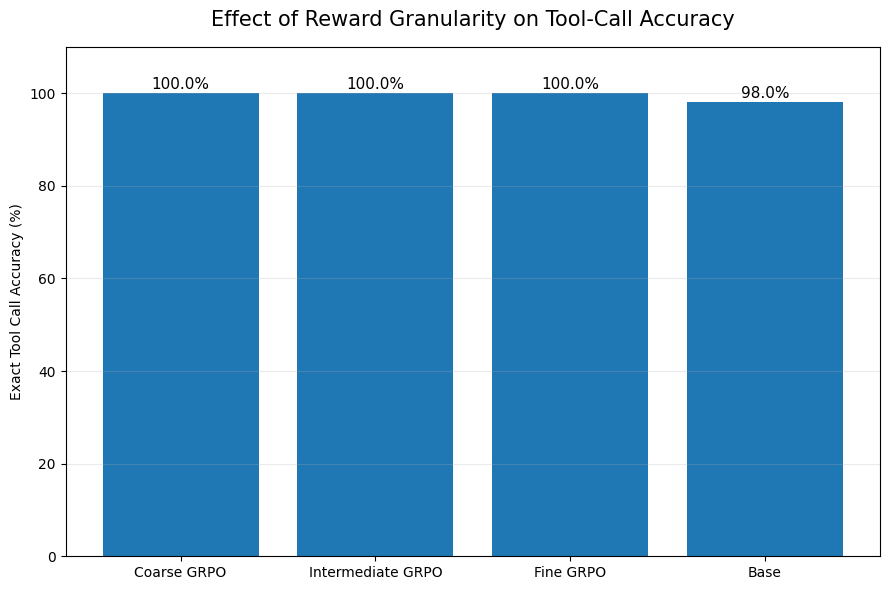

Saved to: /content/drive/MyDrive/ToolRL/results/exact_tool_call_accuracy.png


In [125]:
import matplotlib.pyplot as plt

exact_df = comparison_percent[
    ["Model", "exact_call_accuracy"]
].copy()

exact_df = exact_df.sort_values(
    "exact_call_accuracy",
    ascending=False
)

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    exact_df["Model"],
    exact_df["exact_call_accuracy"]
)

for bar, value in zip(
    bars,
    exact_df["exact_call_accuracy"]
):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Effect of Reward Granularity on Tool-Call Accuracy",
    fontsize=15,
    pad=15
)

ax.set_ylabel("Exact Tool Call Accuracy (%)")
ax.set_ylim(0, 110)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output_path = (
    "/content/drive/MyDrive/ToolRL/results/"
    "exact_tool_call_accuracy.png"
)

RESULT_DIR = "/content/drive/MyDrive/ToolRL/results"
os.makedirs(RESULT_DIR, exist_ok=True)

output_path = f"{RESULT_DIR}/exact_tool_call_accuracy.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", output_path)

Example Check

In [126]:
# Inspect first 10 Fine-model predictions

for i in range(10):
    print("=" * 90)

    print("QUESTION:")
    print(eval_dataset[i]["question"])

    print("\nGOLD TOOL:")
    print(eval_dataset[i]["gold_tool"])

    print("\nGOLD ARGUMENTS:")
    print(eval_dataset[i]["gold_arguments"])
    print("Gold args type:", type(eval_dataset[i]["gold_arguments"]))

    print("\nRAW MODEL OUTPUT:")
    print(fine_results[i]["prediction"])

    print("\nPARSED JSON:")
    print(fine_results[i]["parsed"])

    if fine_results[i]["parsed"] is not None:
        print("\nPARSED KEYS:")
        print(fine_results[i]["parsed"].keys())

    print()

QUESTION:
What is the population of Los Angeles?

GOLD TOOL:
lookup_population

GOLD ARGUMENTS:
{'city': 'Los Angeles', 'expression': None, 'day': None, 'value': None, 'unit': None}
Gold args type: <class 'dict'>

RAW MODEL OUTPUT:
{
  "tool": "lookup_population",
  "arguments": {
    "city": "Los Angeles"
  }
}

PARSED JSON:
{'tool': 'lookup_population', 'arguments': {'city': 'Los Angeles'}}

PARSED KEYS:
dict_keys(['tool', 'arguments'])

QUESTION:
What is 18 multiplied by 4?

GOLD TOOL:
calculator

GOLD ARGUMENTS:
{'city': None, 'expression': '18*4', 'day': None, 'value': None, 'unit': None}
Gold args type: <class 'dict'>

RAW MODEL OUTPUT:
{
  "tool": "calculator",
  "arguments": {
    "expression": "18 * 4"
  }
}

PARSED JSON:
{'tool': 'calculator', 'arguments': {'expression': '18 * 4'}}

PARSED KEYS:
dict_keys(['tool', 'arguments'])

QUESTION:
What is 32 multiplied by 4?

GOLD TOOL:
calculator

GOLD ARGUMENTS:
{'city': None, 'expression': '32*4', 'day': None, 'value': None, 'unit'